<a href="https://colab.research.google.com/github/rokayamohamed2032006-hue/Breast-Cancer-Model/blob/main/Machine_Learning(Breast_Cancer_Model)KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report)

In [ ]:
data = load_breast_cancer(as_frame=True) #Download Breast Cancer Dataset
#there are in the scikit-learn lib.
#as_frame=True -> Pandas convert the dataset into a dataframe
df = data.frame
#Display the first 5 rows of the dataset
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
#Display the number of rows and columns.
print("Dataset Shape:", df.shape)
#Display the column names.
print("\nColumn Names:")
print(df.columns)
#Display basic information about the dataset.
print("\nDataset Information:")
df.info()

Dataset Shape: (569, 31)

Column Names:
Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'target'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    f

In [ ]:
#Display statistical summary of numerical features.
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


target
1    357
0    212
Name: count, dtype: int64


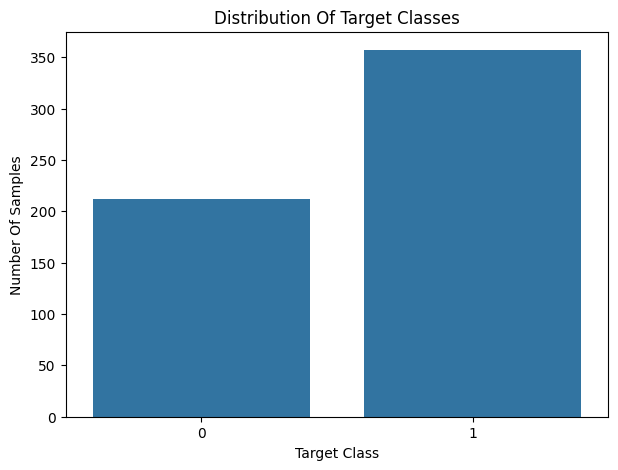

In [ ]:
#Count the samples in each target class.
target_counts = df["target"].value_counts()
print(target_counts)
#Visualize the distribution of target classes.
plt.figure(figsize=(7, 5))
sns.countplot(x="target", data=df) # default bar
plt.title("Distribution Of Target Classes")
plt.xlabel("Target Class")
plt.ylabel("Number Of Samples")
plt.show()

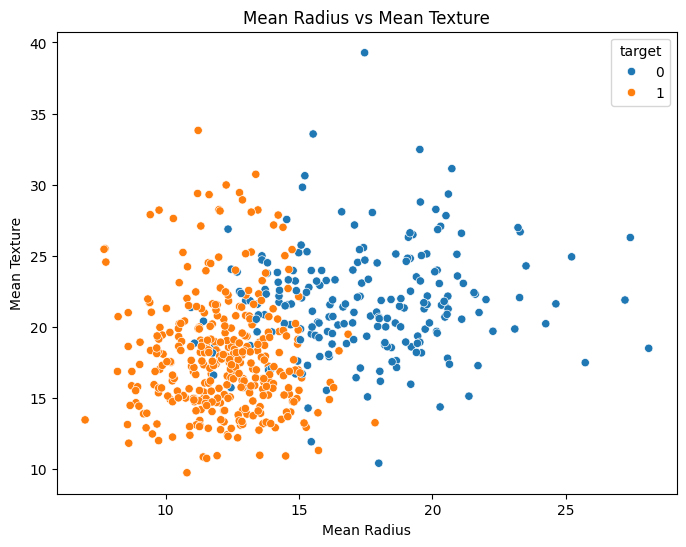

In [ ]:
# Visualize the relationship between two features.
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="mean radius",
    y="mean texture",
    hue="target" #Color the points based on the target class.
    )
plt.title("Mean Radius vs Mean Texture")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.show()

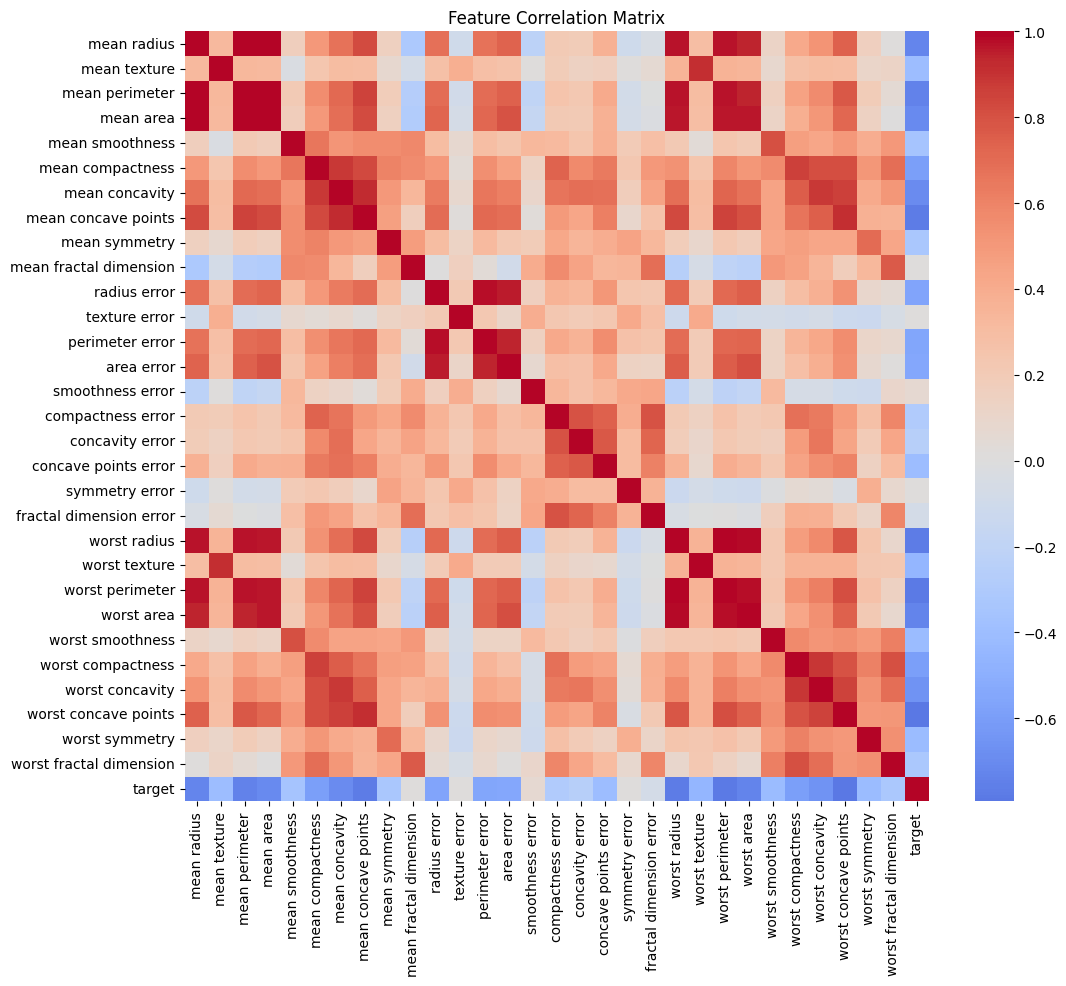

In [ ]:
# Calculate the correlation between numerical features.
correlation_matrix = df.corr()
# Visualize the correlation matrix.
plt.figure(figsize=(12, 10))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)
plt.title("Feature Correlation Matrix")
plt.show()

In [ ]:
# Check for missing values in each column
missing_values = df.isnull().sum()
print(missing_values)

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64


In [ ]:
# Separate the input features from the target variable
X = df.drop("target", axis=1)
# Store the target variable
y = df["target"]
# Display the shapes of X and y
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


In [ ]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# Display the size of each set
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [ ]:
# Create a StandardScaler object
scaler = StandardScaler()
# Fit the scaler on the training data and transform it
X_train_scaled = scaler.fit_transform(X_train)
# Transform the test data using the same scaling parameters
X_test_scaled = scaler.transform(X_test)
# Display the first 5 scaled training samples
print(X_train_scaled[:5])

[[-1.07200079e+00 -6.58424598e-01 -1.08808010e+00 -9.39273639e-01
  -1.35939882e-01 -1.00871795e+00 -9.68358632e-01 -1.10203235e+00
   2.81062120e-01 -1.13231479e-01 -7.04860874e-01 -4.40938351e-01
  -7.43948977e-01 -6.29804931e-01  7.48061001e-04 -9.91572979e-01
  -6.93759567e-01 -9.83284458e-01 -5.91579010e-01 -4.28972052e-01
  -1.03409427e+00 -6.23497432e-01 -1.07077336e+00 -8.76534437e-01
  -1.69982346e-01 -1.03883630e+00 -1.07899452e+00 -1.35052668e+00
  -3.52658049e-01 -5.41380026e-01]
 [ 1.74874285e+00  6.65017334e-02  1.75115682e+00  1.74555856e+00
   1.27446827e+00  8.42288215e-01  1.51985232e+00  1.99466430e+00
  -2.93045055e-01 -3.20179716e-01  1.27567198e-01 -3.81382677e-01
   9.40746962e-02  3.17524379e-01  6.39656015e-01  8.73892616e-02
   7.08450758e-01  1.18215034e+00  4.26212305e-01  7.47970186e-02
   1.22834212e+00 -9.28334970e-02  1.18746742e+00  1.10438613e+00
   1.51700092e+00  2.49654896e-01  1.17859444e+00  1.54991557e+00
   1.91077868e-01 -1.73738602e-01]
 [-9.7

In [ ]:
# Create the KNN classifier with K = 5
knn = KNeighborsClassifier(n_neighbors=5)
# Train the model using the scaled training data
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [ ]:
# Predict the target classes for the test data
y_pred = knn.predict(X_test_scaled)
# Display the first 10 predictions
print("Predicted classes:")
print(y_pred[:10])

Predicted classes:
[0 1 0 0 0 1 1 0 0 0]


In [ ]:
# Calculate the model accuracy
accuracy = accuracy_score(y_test, y_pred)
# Display the accuracy as a percentage
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 95.61%


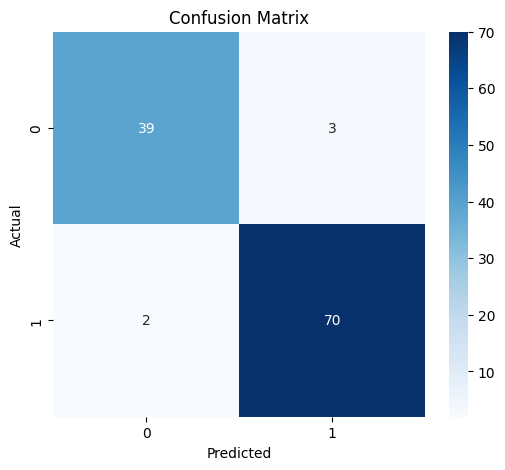

In [ ]:
# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)
# Display the confusion matrix as a heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# Generate a detailed classification report
report = classification_report(y_test, y_pred)
# Display the classification report
print(report)

              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [ ]:
# Display the class names and their corresponding encoded values
print("Class names:", data.target_names)
print("Encoded values:", data.target)

Class names: ['malignant' 'benign']
Encoded values: 0      0
1      0
2      0
3      0
4      0
      ..
564    0
565    0
566    0
567    0
568    1
Name: target, Length: 569, dtype: int64


In [ ]:
# Import tools for cross-validation and model selection
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
# Create a pipeline that scales the data and applies KNN
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])
# Define the K values to test
param_grid = {
    "knn__n_neighbors": range(1, 21)
}
# Search for the best K using cross-validation
grid_search = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=5,
    scoring="accuracy"
)
# Train and evaluate the different K values
grid_search.fit(X_train, y_train)
# Display the best K value and its cross-validation accuracy
print("Best K:", grid_search.best_params_["knn__n_neighbors"])
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best K: 7
Best Cross-Validation Accuracy: 0.9714285714285715


In [ ]:
# Select the best KNN model found by GridSearchCV
best_knn = grid_search.best_estimator_
# Make predictions on the untouched test data
y_pred_best = best_knn.predict(X_test)
# Calculate the final test accuracy
final_accuracy = accuracy_score(y_test, y_pred_best)
# Display the final accuracy
print(f"Final Test Accuracy: {final_accuracy:.2%}")

Final Test Accuracy: 97.37%


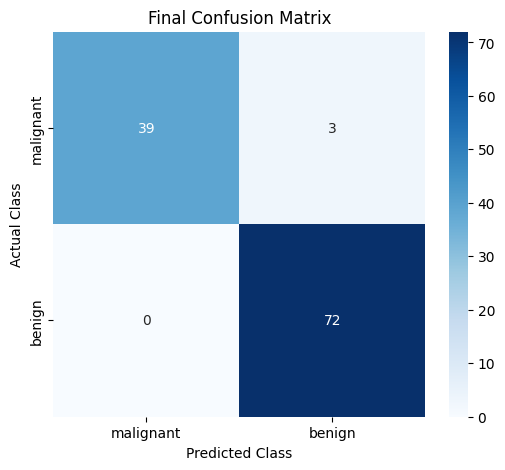

In [ ]:
# Calculate the final confusion matrix
final_cm = confusion_matrix(y_test, y_pred_best)
# Visualize the confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)
plt.title("Final Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [ ]:
# Generate the final classification report
final_report = classification_report(
    y_test,
    y_pred_best,
    target_names=data.target_names
)
# Display the classification report
print(final_report)

              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



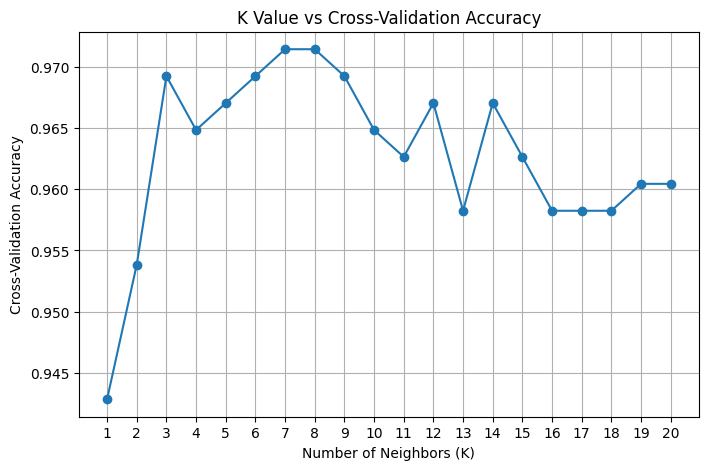

In [ ]:
# Convert the cross-validation results into a DataFrame
results = pd.DataFrame(grid_search.cv_results_)
# Extract the tested K values
k_values = results["param_knn__n_neighbors"].astype(int)
# Extract the mean cross-validation accuracy
cv_accuracy = results["mean_test_score"]
# Plot K values against cross-validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    cv_accuracy,
    marker="o"
)
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Cross-Validation Accuracy")
plt.title("K Value vs Cross-Validation Accuracy")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [ ]:
# Select one sample from the test set
sample = X_test.iloc[[0]]
# Get the actual class of the sample
actual_class = y_test.iloc[0]
# Predict the class using the final KNN model
predicted_class = best_knn.predict(sample)[0]
# Display the prediction and the actual class
print("Predicted Class:", data.target_names[predicted_class])
print("Actual Class:", data.target_names[actual_class])

Predicted Class: malignant
Actual Class: malignant


In [ ]:
# Get the best K value selected by GridSearchCV
best_k = grid_search.best_params_["knn__n_neighbors"]
# Get the best cross-validation accuracy
best_cv_accuracy = grid_search.best_score_
# Display the final model summary
print("===== Final Model Summary =====")
print(f"Best K: {best_k}")
print(f"Cross-Validation Accuracy: {best_cv_accuracy:.2%}")
print(f"Final Test Accuracy: {final_accuracy:.2%}")

===== Final Model Summary =====
Best K: 7
Cross-Validation Accuracy: 97.14%
Final Test Accuracy: 97.37%
